In [59]:
from scipy.io import wavfile
import numpy as np

sample_rate, signal = wavfile.read('Data/AllSongsWhistled/wav/NocturneOfShadow.wav')
signal = signal.T[0]

In [60]:
signal_before = signal.copy()

In [ ]:
SILENCE_DETECION_SMOOTHING_WINDOWS = 10 # ms
SILENCE_DETECTION_REFERENCE_PERCENTILE = 99 # between 0 and 100
SILENCE_DETECTION_THRESHOLD_FACTOR = 0.1

def removeSilences(x : np.ndarray, fs : int):
    x_res = x.copy()
    window_size = int(SILENCE_DETECION_SMOOTHING_WINDOWS * fs / 1000)  # ms to s conversion
    envelope = np.convolve(a=np.abs(x.astype(float)), v=np.ones(window_size)/window_size, mode='same')

    # Estimate the reference amplitude and define the silence threshold
    reference_amplitude = np.percentile(envelope, SILENCE_DETECTION_REFERENCE_PERCENTILE)
    silence_threshold = SILENCE_DETECTION_THRESHOLD_FACTOR * reference_amplitude

    # Identify non-silent samples
    silence_mask = envelope < silence_threshold

    # Remove silent samples for testing
    x_res[silence_mask] = 0
    return x_res


In [67]:
signal_no_silence = removeSilences(x=signal, fs=sample_rate)

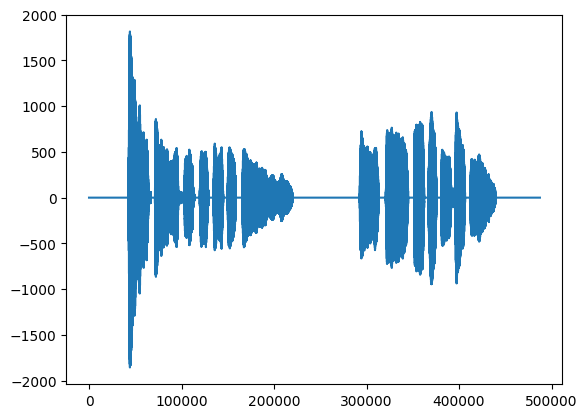

In [68]:
import matplotlib.pyplot as plt

plt.plot(signal_no_silence)

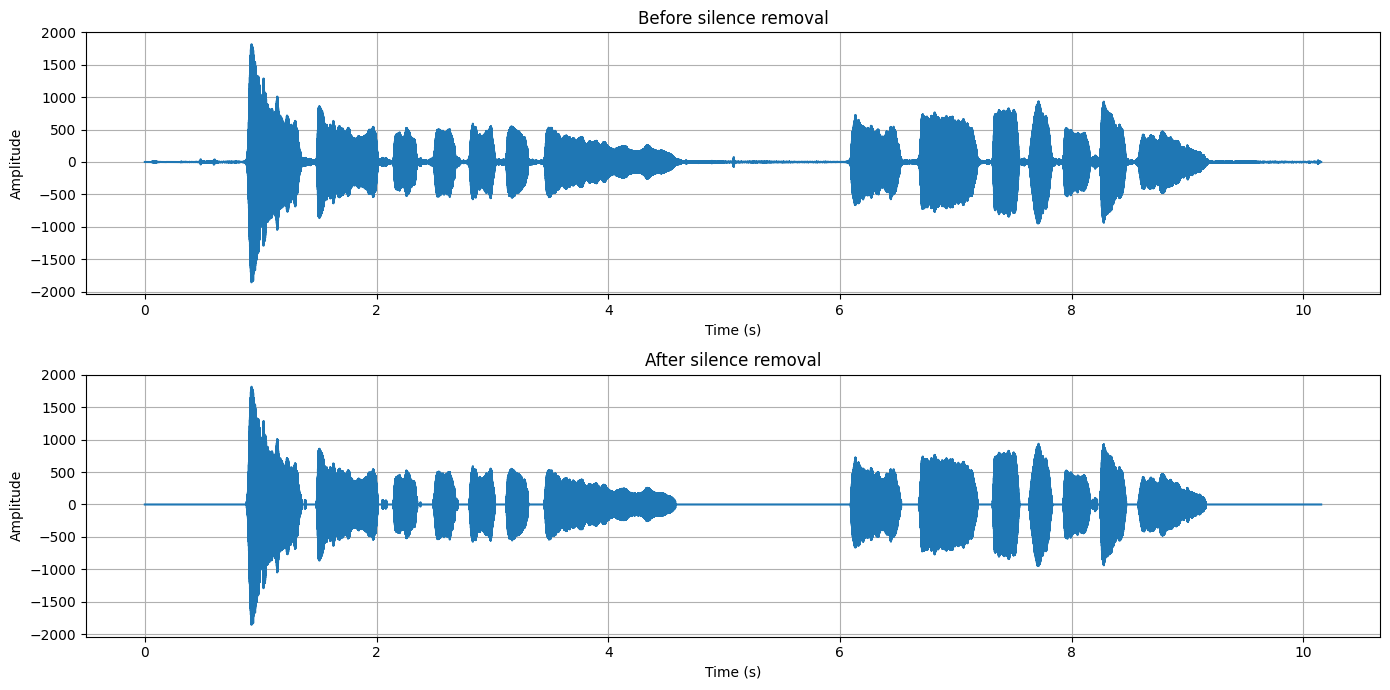

In [69]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Original signal
time_before = np.arange(len(signal)) / sample_rate
axes[0].plot(time_before, signal)
axes[0].set_title("Before silence removal")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

# Signal after silence removal
time_after = np.arange(len(signal_no_silence)) / sample_rate
axes[1].plot(time_after, signal_no_silence)
axes[1].set_title("After silence removal")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

In [71]:
from scipy.ndimage import median_filter

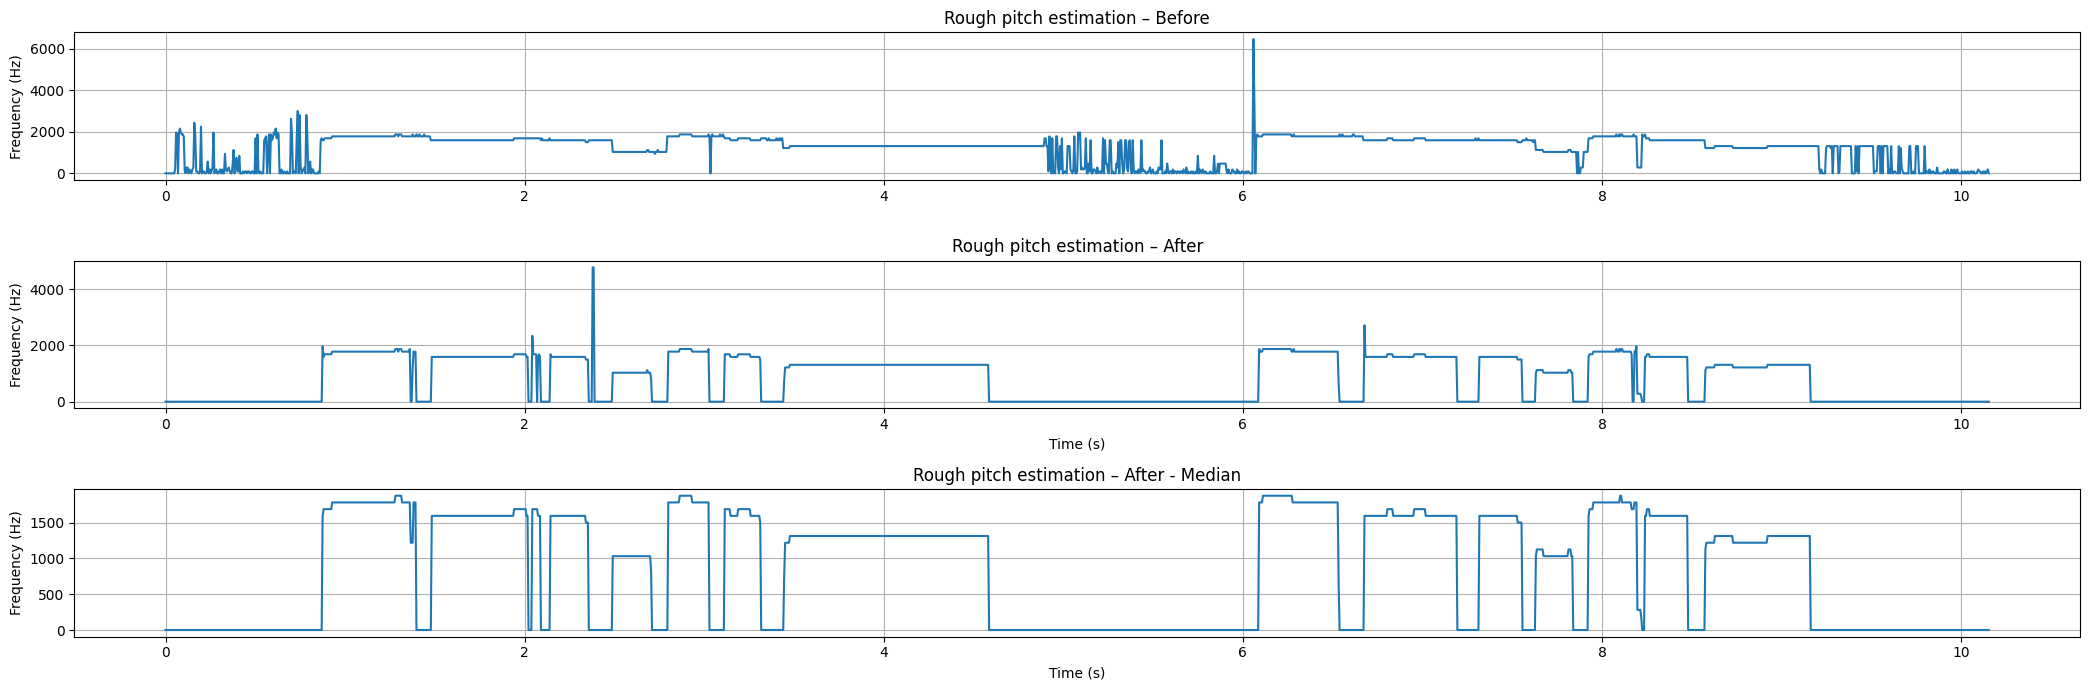

In [72]:
# Rough pitch estimation using the dominant STFT frequency bin
import scipy.signal as sig
def rough_pitch(signal):
    f, t, Zxx = sig.stft(signal, sample_rate, nperseg=512)
    pitch = f[np.argmax(np.abs(Zxx), axis=0)]
    return t, pitch

t_before, pitch_before = rough_pitch(signal_before)
t_after, pitch_after = rough_pitch(signal_no_silence)
pitch_after_med = median_filter(pitch_after, size=5)

fig, axes = plt.subplots(3, 1, figsize=(21, 7))

axes[0].plot(t_before, pitch_before)
axes[0].set_title("Rough pitch estimation – Before")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].grid()

axes[1].plot(t_after, pitch_after)
axes[1].set_title("Rough pitch estimation – After")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].grid()

axes[2].plot(t_after, pitch_after_med)
axes[2].set_title("Rough pitch estimation – After - Median")
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Frequency (Hz)")
axes[2].grid()

plt.tight_layout()
plt.show()